In [ ]:
import os
from pathlib import Path

PROJECT_ROOT = Path(os.environ["VLA_CLASS_ROOT"])

import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

In [2]:
import matplotlib.pyplot as plt
import cv2
import numpy as np

def display_image(image, depth=False, colormap=cv2.COLORMAP_JET):
    """
    显示图像
    
    参数:
        image: 输入图像
        depth: 是否为深度图，默认False
        colormap: 深度图的伪彩色映射，默认COLORMAP_JET
    """
    if depth:
        # 深度图处理
        # 归一化到 0-255
        depth_normalized = cv2.normalize(image, None, 0, 255, cv2.NORM_MINMAX)
        depth_uint8 = depth_normalized.astype(np.uint8)
        
        # 应用伪彩色
        depth_colored = cv2.applyColorMap(depth_uint8, colormap)
        
        # BGR -> RGB (OpenCV 输出是 BGR)
        depth_colored = cv2.cvtColor(depth_colored, cv2.COLOR_BGR2RGB)
        
        plt.imshow(depth_colored)
    elif image.ndim == 2:
        # 灰度图，直接显示
        plt.imshow(image, cmap='gray')
    elif image.ndim == 3 and image.shape[2] in [3, 4]:
        # 彩色图
        plt.imshow(image)
    else:
        raise ValueError("输入的图像格式不正确")

    plt.axis('off')
    plt.show()

In [3]:
# 定义数据变换：转Tensor + 标准化
transform = transforms.Compose([
    transforms.ToTensor(),                       # [0,255] → [0,1]
    transforms.Normalize((0.1307,), (0.3081,))   # MNIST的均值和标准差
])

In [ ]:
# 加载MNIST数据集
train_ds = datasets.MNIST(root=PROJECT_ROOT / "data", train=True, download=True, transform=transform)
test_ds  = datasets.MNIST(root=PROJECT_ROOT / "data", train=False, download=True, transform=transform)

print(f"训练集: {len(train_ds)} 样本")
print(f"测试集: {len(test_ds)} 样本")

In [5]:
# 查看单个样本
image, label = train_ds[0]
print(f"图像形状: {image.shape}")  # [C, H, W]
print(f"标签: {label}")

图像形状: torch.Size([1, 28, 28])
标签: 5


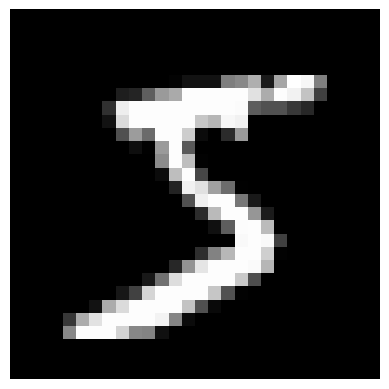

In [7]:
display_image(image.squeeze().numpy())  # 去掉通道维度，显示灰度图

In [8]:
# 创建DataLoader：批量加载
train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)

# 获取一个batch
images, labels = next(iter(train_loader))
print(f"Batch图像形状: {images.shape}")  # [B, C, H, W]
print(f"Batch标签形状: {labels.shape}")

Batch图像形状: torch.Size([64, 1, 28, 28])
Batch标签形状: torch.Size([64])
